# Capstone: Diamond Price Prediction

**Problem statement:** Build a machine learning model that predicts the price of a diamond from its measurable attributes, so that a retailer can set consistent prices quickly and spot stones that are priced out of line.

**Objectives**
1. Prepare and explore a real-world dataset.
2. Train and compare regression models.
3. Evaluate with appropriate metrics and analyse where the model makes errors.
4. Turn the results into practical recommendations.

**Scope:** 53,940 raw records (seaborn-data Diamonds dataset). Target: `price` in USD. **Success criteria:** R² above 0.95 on unseen data and an average error well under 10% of price.

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
sns.set_theme(style='whitegrid', palette='deep'); os.makedirs('figs',exist_ok=True)
df=pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv')
print('Raw shape:',df.shape)

Raw shape: (53940, 10)


## 1. Data preparation
Duplicates are removed **before** splitting so identical rows cannot appear in both training and test sets (data leakage). Zero dimensions are treated as missing and imputed by carat decile; physically impossible records are removed.

In [2]:
df=df.drop_duplicates()
df[['x','y','z']]=df[['x','y','z']].replace(0,np.nan)
df['cb']=pd.qcut(df['carat'],10,duplicates='drop')
for c in ['x','y','z']:
    df[c]=df[c].fillna(df.groupby('cb',observed=True)[c].transform('median'))
df=df.drop(columns='cb')
bad=(df.y>20)|(df.z>20)|(df.depth<40)|(df.depth>80)|(df.table>90)
df=df[~bad].reset_index(drop=True)
print('Clean shape:',df.shape,'| missing:',int(df.isna().sum().sum()))
df.describe().T.round(2)

Clean shape: (53790, 10) | missing: 0


,count,mean,std,min,25%,50%,75%,max
carat,53790.0,0.80,0.47,0.20,0.40,0.70,1.04,5.01
depth,53790.0,61.75,1.43,43.00,61.00,61.80,62.50,79.00
table,53790.0,57.46,2.23,43.00,56.00,57.00,59.00,79.00
price,53790.0,3932.81,3987.88,326.00,951.00,2401.00,5325.75,18823.00
x,53790.0,5.73,1.12,3.73,4.71,5.70,6.54,10.74
y,53790.0,5.73,1.11,3.68,4.72,5.71,6.54,10.54
z,53790.0,3.54,0.69,1.07,2.91,3.53,4.04,6.98


## 2. Exploratory analysis

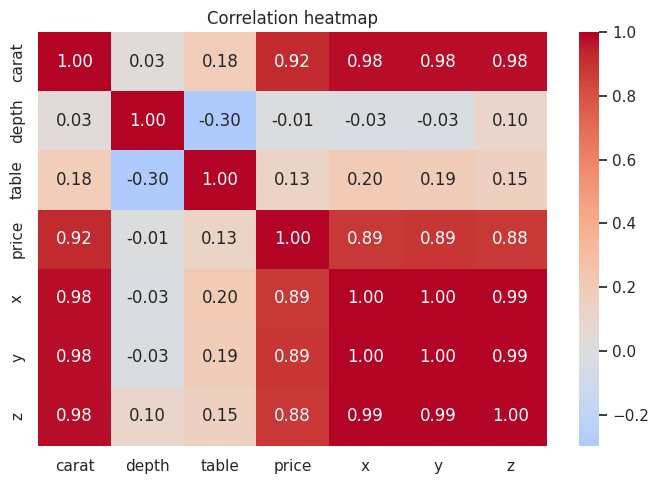

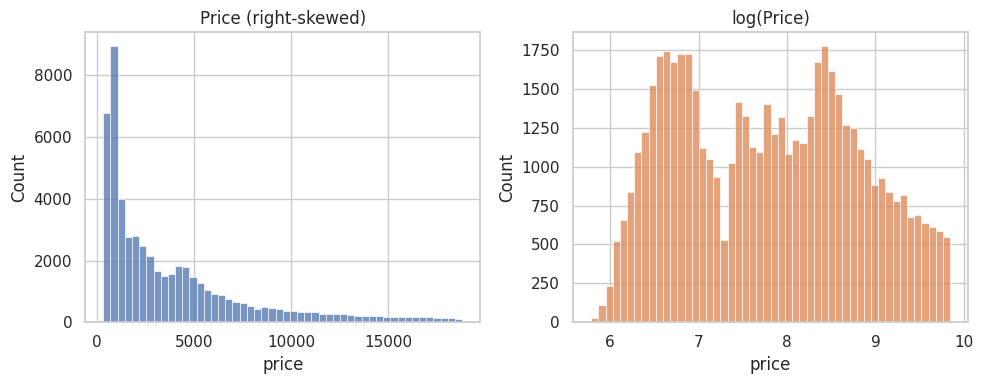

Skew price: 1.62 | Skew log price: 0.11


In [3]:
num=['carat','depth','table','price','x','y','z']
plt.figure(figsize=(7,5)); sns.heatmap(df[num].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0); plt.title('Correlation heatmap'); plt.tight_layout(); plt.savefig('figs/heatmap.png',dpi=130); plt.show()
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.histplot(df.price,bins=50,ax=ax[0]); ax[0].set_title('Price (right-skewed)')
sns.histplot(np.log(df.price),bins=50,ax=ax[1],color='C1'); ax[1].set_title('log(Price)')
plt.tight_layout(); plt.savefig('figs/price_dist.png',dpi=130); plt.show()
print('Skew price:',round(df.price.skew(),2),'| Skew log price:',round(np.log(df.price).skew(),2))

## 3. Feature engineering
- `cut`, `color`, `clarity` encoded as ordinal numbers (they have a natural quality order)
- `volume` = x*y*z
- Target transformed to `log(price)` because price is right-skewed and effects are multiplicative; predictions are converted back to dollars for evaluation

In [4]:
cut=['Fair','Good','Very Good','Premium','Ideal']; col=list('JIHGFED'); cla=['I1','SI2','SI1','VS2','VS1','VVS2','VVS1','IF']
X=df[['carat','depth','table','x','y','z']].copy()
X['volume']=df.x*df.y*df.z
X['cut']=df.cut.map({c:i for i,c in enumerate(cut)})
X['color']=df.color.map({c:i for i,c in enumerate(col)})   # higher = better colour (D)
X['clarity']=df.clarity.map({c:i for i,c in enumerate(cla)})
y=np.log(df.price)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape,X_test.shape)

(43032, 10) (10758, 10)


## 4. Model building
Three models of increasing complexity are compared on the same split:
1. **Linear regression** on log price with log carat (baseline, interpretable)
2. **Random forest**
3. **Gradient boosting** (HistGradientBoostingRegressor)

In [5]:
def evaluate(name,pred_log,store):
    p=np.exp(pred_log); a=np.exp(y_test)
    store.append({'Model':name,'R2':r2_score(a,p),'MAE ($)':mean_absolute_error(a,p),'RMSE ($)':np.sqrt(mean_squared_error(a,p)),'MAPE (%)':np.mean(np.abs(a-p)/a)*100})
res=[]; preds={}
Xl_train=X_train.copy(); Xl_test=X_test.copy()
for d in (Xl_train,Xl_test): d['log_carat']=np.log(d.carat)
lin=LinearRegression().fit(Xl_train[['log_carat','cut','color','clarity','depth','table']],y_train)
preds['Linear regression']=lin.predict(Xl_test[['log_carat','cut','color','clarity','depth','table']])
rf=RandomForestRegressor(n_estimators=150,min_samples_leaf=2,random_state=42,n_jobs=-1).fit(X_train,y_train)
preds['Random forest']=rf.predict(X_test)
gb=HistGradientBoostingRegressor(max_iter=400,learning_rate=0.08,max_leaf_nodes=31,random_state=42).fit(X_train,y_train)
preds['Gradient boosting']=gb.predict(X_test)
for k,v in preds.items(): evaluate(k,v,res)
results=pd.DataFrame(res).set_index('Model'); results.round(3)

,R2,MAE ($),RMSE ($),MAPE (%)
Model,,,,
Linear regression,0.944,450.697,918.879,11.389
Random forest,0.982,257.196,525.295,6.296
Gradient boosting,0.982,256.593,521.192,6.217


## 5. Evaluation: cross-validation of the best model

In [6]:
best=results['RMSE ($)'].idxmin(); print('Best model by RMSE:',best)
cv=cross_val_score(HistGradientBoostingRegressor(max_iter=400,learning_rate=0.08,max_leaf_nodes=31,random_state=42),X,y,cv=KFold(5,shuffle=True,random_state=1),scoring='r2')
print('5-fold CV R2 on log price:',cv.round(4),'| mean',cv.mean().round(4))

Best model by RMSE: Gradient boosting


5-fold CV R2 on log price: [0.9926 0.9927 0.9929 0.9927 0.992 ] | mean 0.9926


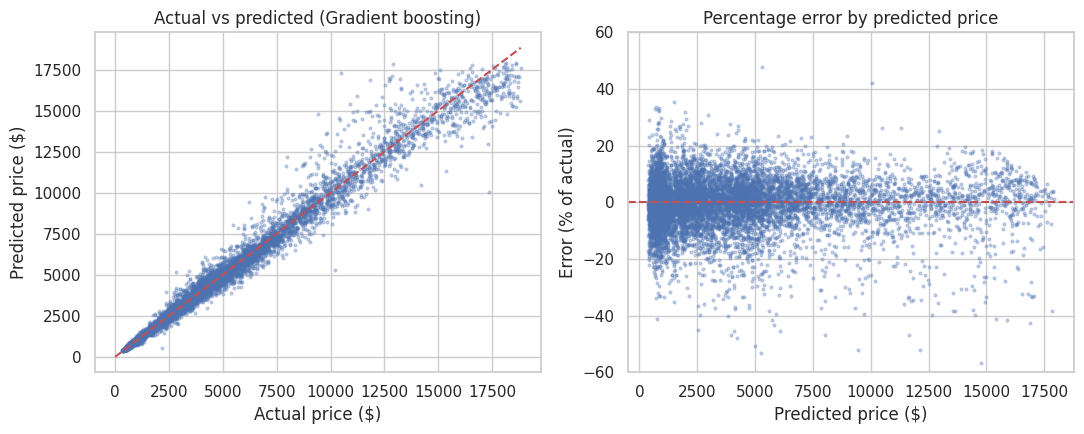

In [7]:
p=np.exp(preds[best]); a=np.exp(y_test)
fig,ax=plt.subplots(1,2,figsize=(11,4.5))
ax[0].scatter(a,p,s=4,alpha=.3); m=max(a.max(),p.max()); ax[0].plot([0,m],[0,m],'r--'); ax[0].set_xlabel('Actual price ($)'); ax[0].set_ylabel('Predicted price ($)'); ax[0].set_title('Actual vs predicted ('+best+')')
ax[1].scatter(p,(a-p)/a*100,s=4,alpha=.3); ax[1].axhline(0,color='r',ls='--'); ax[1].set_xlabel('Predicted price ($)'); ax[1].set_ylabel('Error (% of actual)'); ax[1].set_title('Percentage error by predicted price'); ax[1].set_ylim(-60,60)
plt.tight_layout(); plt.savefig('figs/actual_vs_pred.png',dpi=130); plt.show()

## 6. Error analysis

          n      MAE  MAPE
band                      
0-0.5  3729    48.21  5.59
0.5-1  3620   175.78  6.12
1-1.5  2387   401.50  6.56
1.5-2   682   789.71  7.36
2+      340  1315.78  9.43


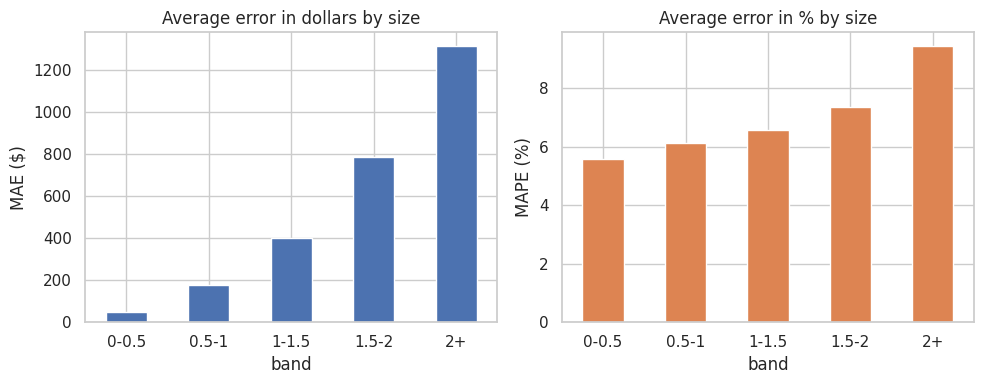

Share of predictions within 10% of actual: 81.1 %
Share within 20%: 96.6 %
Worst 5 by % error:
       actual      pred  carat  abs_pct  abs_err   band
2690   2845.0   5165.60   1.27    81.57  2320.60  1-1.5
4611   2160.0    540.85   0.34    74.96  1619.15  0-0.5
3899   2360.0   3969.06   1.20    68.18  1609.06  1-1.5
8631  10470.0  17291.31   2.46    65.15  6821.31     2+
3377   9425.0  14764.83   1.65    56.66  5339.83  1.5-2


In [8]:
err=pd.DataFrame({'actual':a.values,'pred':p,'carat':X_test.carat.values}); err['abs_pct']=np.abs(err.actual-err.pred)/err.actual*100; err['abs_err']=np.abs(err.actual-err.pred)
err['band']=pd.cut(err.carat,[0,.5,1,1.5,2,6],labels=['0-0.5','0.5-1','1-1.5','1.5-2','2+'])
eb=err.groupby('band',observed=True).agg(n=('abs_pct','size'),MAE=('abs_err','mean'),MAPE=('abs_pct','mean')).round(2); print(eb)
fig,ax=plt.subplots(1,2,figsize=(10,4))
eb.MAE.plot(kind='bar',ax=ax[0],rot=0,color='C0'); ax[0].set_ylabel('MAE ($)'); ax[0].set_title('Average error in dollars by size')
eb.MAPE.plot(kind='bar',ax=ax[1],rot=0,color='C1'); ax[1].set_ylabel('MAPE (%)'); ax[1].set_title('Average error in % by size')
plt.tight_layout(); plt.savefig('figs/error_by_band.png',dpi=130); plt.show()
print('Share of predictions within 10% of actual:',round((err.abs_pct<=10).mean()*100,1),'%')
print('Share within 20%:',round((err.abs_pct<=20).mean()*100,1),'%')
print('Worst 5 by % error:'); print(err.sort_values('abs_pct',ascending=False).head(5).round(2))

## 7. Feature importance (permutation importance on the test set)

carat      0.3364
y          0.2322
clarity    0.0847
x          0.0805
volume     0.0438
color      0.0383
z          0.0154
cut        0.0021
depth      0.0010
table      0.0004
dtype: float64


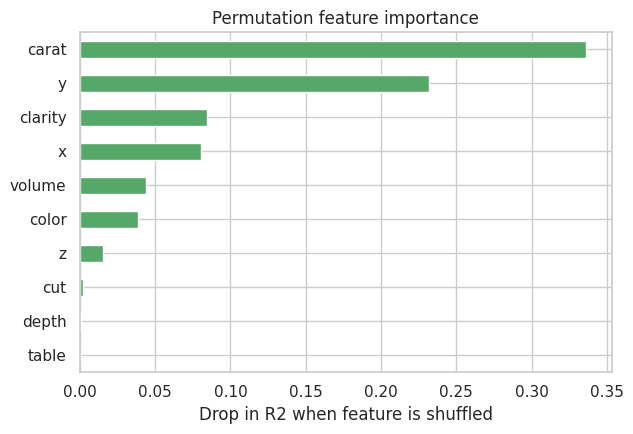

In [9]:
best_model={'Linear regression':None,'Random forest':rf,'Gradient boosting':gb}[best]
pi=permutation_importance(best_model,X_test,y_test,n_repeats=5,random_state=0,scoring='r2',n_jobs=1)
imp=pd.Series(pi.importances_mean,X.columns).sort_values()
print(imp.round(4).sort_values(ascending=False))
plt.figure(figsize=(6.5,4.5)); imp.plot(kind='barh',color='C2'); plt.xlabel('Drop in R2 when feature is shuffled'); plt.title('Permutation feature importance'); plt.tight_layout(); plt.savefig('figs/importance.png',dpi=130); plt.show()

## 8. Insights and recommendations
See the written report for interpretation. The model reproduces prices closely for most stones (about 81% of predictions are within 10% of the actual price). Errors grow with size: the average error is about 5.6% for stones up to 0.5 carat and about 9.4% for stones above 2 carats, and it is largest in dollar terms for the most expensive stones. The model should be used as a pricing guide and a flag for out-of-line stones, not as a replacement for expert judgement.